# 📘 11.4 Stability of Finite Difference Methods

In Notebook **11.1**, we used the **Forward in Time, Centred in Space (FTCS)** method to simulate diffusion and derived a condition that restricts its time step. In Notebook **11.3**, we solved a steady-state elliptic PDE and distinguished a small *linear-system residual* from genuine *grid convergence*.

We will now bring these ideas together: **When should we trust a time-dependent finite-difference solution?** A simulation can run without Python errors and still produce growing oscillations that have no physical meaning. Conversely, a simulation may be stable but not sufficiently accurate for an engineering decision.

Using the familiar one-dimensional diffusion equation, we will interpret the FTCS stability limit, investigate unstable solutions through commented Python examples and an interactive stability explorer, and see why a finer spatial grid may require a much smaller time step. We will also briefly compare the **Fourier number** used for diffusion with the **Courant number** used for advection.

### 🎯 Learning Objectives

> By the end of this notebook, you should be able to:
>
> * **Explain** numerical stability in terms of how small perturbations behave as a numerical solution advances.
> * **Calculate** the FTCS diffusion number and the maximum stable time step for a one-dimensional uniform grid.
> * **Interpret** the difference between decaying, sign-alternating and growing numerical errors.
> * **Distinguish** the Fourier (diffusion) number from the Courant number and recognise that their stability limits depend on the governing PDE and numerical scheme.
> * **Use interactive controls** to test how space and time discretisation affect FTCS stability.
> * **Predict and measure** how refining a spatial grid changes the stable time step, computational work and numerical error.
> * **Separate** time-marching stability from numerical accuracy, grid convergence and convergence of a linear-system solver.

## 📂 11.4.0 How to use this notebook

This notebook builds directly on **11.1 (FTCS)** and **11.3 (elliptic PDEs)**. You do **not** need to repeat the full von Neumann derivation from 11.1; here we concentrate on interpreting and applying its result.

Follow this sequence:

1. **Predict** whether a small error should grow or decay in a diffusion problem.
2. **Calculate** the diffusion number $r=D\Delta t/(\Delta x)^2$ and check whether the chosen time step is allowed.
3. **Run Example 1** to observe the behaviour of small numerical perturbations.
4. **Use the interactive explorer** to change the number of spatial nodes and time steps, while keeping the same physical simulation duration.
5. **Run Example 2** to refine the grid while maintaining stability, then compare errors and computational work.
6. **Interpret** the output: a stable result is not automatically an accurate or validated result.

Run the Python cells **in order**. The interactive explorer and Example 2 both reuse the small FTCS function introduced in Example 1. The explorer uses **ipywidgets**, a Jupyter package that displays dropdown menus and sliders. Its setup cell can install the package if necessary.

If your notebook cannot show interactive widgets, you can still call the plotting function directly with new values (instructions are included below).

## 📂 11.4.1 Why can a diffusion calculation become unstable?

Physical diffusion tends to smooth spatial differences. For example, consider heat conduction in a thin rod with fixed temperatures at its ends. A local temperature disturbance should spread and diminish rather than develop ever-larger point-to-point oscillations.

The governing PDE is

$$\frac{\partial T}{\partial t}=D\frac{\partial^2 T}{\partial x^2},\qquad D>0,$$

where $T(x,t)$ is temperature and $D$ is the thermal diffusivity (units of $\mathrm{m^2/s}$). The same equation could represent the diffusion of a concentration, with $T$ replaced by an appropriate scalar field.

A finite-difference calculation uses approximations. Small errors may arise from discretisation, rounding or imperfect initial data. The central question is **what the numerical method does to these errors at each time step**.

If a particular small error changes according to

$$\delta^{n+1}=A\,\delta^n,$$

then $A$ is its **amplification factor**, as discussed in the ODE stability topic and Notebook 11.1.

| Behaviour of the error mode | Interpretation |
|---|---|
| $0<A<1$ | The error decreases without changing sign. |
| $-1<A<0$ | The error alternates in sign but its magnitude decreases. |
| $|A|>1$ | The error grows from step to step: an unstable numerical mode. |

> **Important:** A negative amplification factor is **not** automatically unstable. What matters for this simple mode is its **magnitude**, $|A|$. The physical solution and the numerical error are also different things: a decaying error mode does not necessarily imply visible oscillations in the full temperature field.

## 📂 11.4.2 Revisit the FTCS stability limit

For an equally spaced one-dimensional grid, let $j$ identify a spatial node and $n$ identify a time level. FTCS uses a **forward difference in time** and a **centred second difference in space**:

$$\frac{T_j^{n+1}-T_j^n}{\Delta t}=D\frac{T_{j-1}^n-2T_j^n+T_{j+1}^n}{(\Delta x)^2}.$$

**Step 1 — Solve for the temperature at the next time level:**

$$\boxed{T_j^{n+1}=T_j^n+r\left(T_{j-1}^n-2T_j^n+T_{j+1}^n\right),}\qquad
r=\frac{D\Delta t}{(\Delta x)^2}.$$

All the values on the right-hand side are known at time level $n$. This is why FTCS is an **explicit** method.

**Step 2 — Apply the stability result from Notebook 11.1.** Its von Neumann analysis gave

$$A(k)=1-4r\sin^2\left(\frac{k\Delta x}{2}\right).$$

The most rapidly alternating spatial modes impose the strictest restriction. Requiring $|A(k)|\leq 1$ for every mode gives, for this particular FTCS diffusion scheme,

$$\boxed{0\le r\le\frac12\quad\Longleftrightarrow\quad
\Delta t\le\frac{(\Delta x)^2}{2D}.}$$

**Step 3 — Use the condition before running the solver.**

Suppose $D=0.10\;\mathrm{m^2/s}$ and $\Delta x=0.02\;\mathrm m$. Then

$$\Delta t_{\max}=\frac{(0.02)^2}{2(0.10)}=0.002\;\mathrm s.$$

A time step of $0.0016\;\mathrm s$ gives $r=0.40$ and satisfies the condition. A time step of $0.0024\;\mathrm s$ gives $r=0.60$ and violates it.

> The values of $D$ used in this notebook are **illustrative**, not material data for a specific real rod. The stability condition is specific to the **one-dimensional, constant-$D$, uniform-grid FTCS diffusion scheme**. Different PDEs and discretisations may have different limits.

## 📂 11.4.3 Courant number or Fourier number?

You may also hear the term **CFL condition** when discussing numerical PDE stability. It is related, but we should distinguish two different dimensionless numbers.

| | Advection / wave transport | Diffusion / heat conduction |
|---|---|---|
| Dimensionless number | **Courant number**, $C$ (or $\mathrm{Co}$) | **Fourier number**, $\mathrm{Fo}$ (called $r$ here) |
| Definition | $\displaystyle C=\frac{|u|\Delta t}{\Delta x}$ | $\displaystyle r=\frac{D\Delta t}{(\Delta x)^2}$ |
| Meaning | Distance transported in one time step, relative to one cell width | Strength of diffusion over one time step, relative to the spatial grid |
| Illustrative explicit stability condition | $C\le 1$ for **1D first-order upwind advection** | $r\le 1/2$ for **1D FTCS diffusion** |

Here $u$ is an advection velocity (units $\mathrm{m/s}$), and $D$ is a diffusivity (units $\mathrm{m^2/s}$).

The **Courant–Friedrichs–Lewy (CFL) principle** concerns whether the numerical method can represent the physical propagation of information. It is especially useful for advection and wave problems, where disturbances propagate at a finite speed. The familiar $C\le1$ rule is **not universal**: it depends on the particular numerical scheme, and satisfying a CFL restriction alone does not prove that every scheme is stable.

For *diffusion*, the Fourier number is the more useful parameter. In particular, when the spatial spacing is **halved**:

- At unchanged $\Delta t$, the **Courant number doubles** (for fixed $u$).
- At unchanged $\Delta t$, the **Fourier number quadruples** (for fixed $D$).

Consequently, maintaining the same Fourier number requires **quartering** the time step. This difference becomes important when we refine a diffusion grid in Example 2.

> **Connection to Week 10:** Notebook 10.4 introduced parabolic (diffusion) and hyperbolic (wave/advection) PDEs. Their different physical behaviour helps explain why different dimensionless stability parameters arise. We will **not** derive or implement a separate advection solver here.

## 📂 11.4.4 Example 1 — Observe stable and unstable perturbations

In the Fourier-mode expression from 11.1, the most rapidly alternating modes have an amplification factor approximately equal to

$$A_{\mathrm{high}}\approx1-4r.$$

This gives a useful way to predict what happens to a small point-to-point error:

| Diffusion number | Approximate $A_{\mathrm{high}}$ | Expected error behaviour |
|---|---:|---|
| $r=0.20$ | $0.20$ | Decays without changing sign |
| $r=0.40$ | $-0.60$ | Alternates in sign but decays |
| $r=0.60$ | $-1.40$ | Alternates and grows |

**Numerical experiment.** Start with a smooth temperature profile in a rod of length $L=1\;\mathrm m$, with the temperatures at both ends fixed at zero:

$$T(x,0)=\sin\left(\frac{\pi x}{L}\right).$$

We run the solver twice: first with this smooth profile, and then with a **small, rapidly alternating disturbance** added to the initial profile. Comparing the two calculations isolates what the numerical method does to that disturbance.

The disturbance is chosen to be compatible with the two fixed-end temperatures. For this finite grid, its exact amplification factor is very close to (but not exactly) $1-4r$. No additional Fourier derivation is needed to interpret the plots.

**Before running:** Which case do you expect to grow? Does a sign-alternating disturbance always mean instability?

r = 0.20 | dt = 0.001250 s | approx. high-mode A = +0.20 | disturbance growth after 4 steps = 0.00164x
  Signed amplitude at steps 0–3: +1.000, +0.201, +0.040, +0.008
r = 0.40 | dt = 0.002500 s | approx. high-mode A = -0.60 | disturbance growth after 4 steps = 0.127x
  Signed amplitude at steps 0–3: +1.000, -0.598, +0.357, -0.213
r = 0.60 | dt = 0.003750 s | approx. high-mode A = -1.40 | disturbance growth after 4 steps = 3.8x
  Signed amplitude at steps 0–3: +1.000, -1.396, +1.950, -2.722


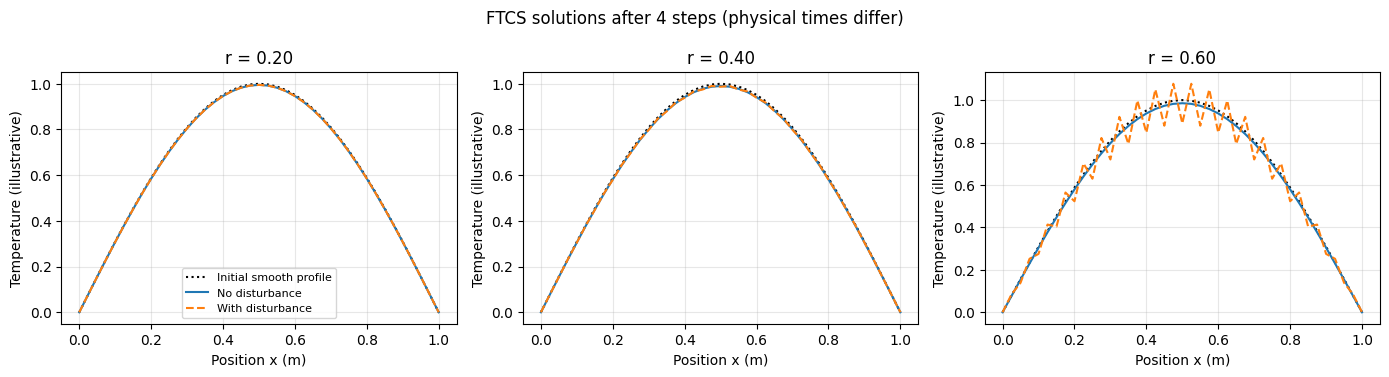

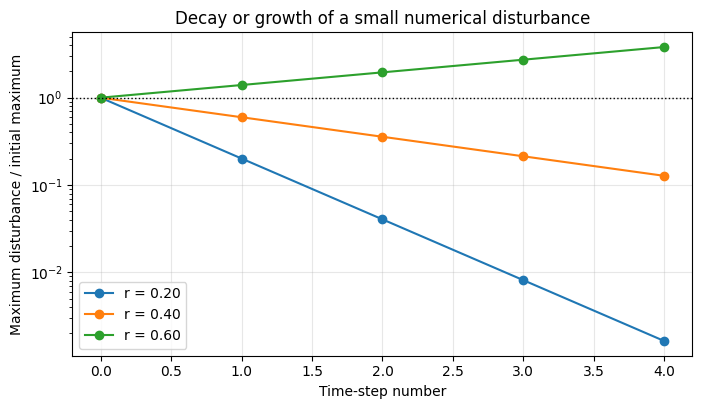

In [ ]:
# @title 💻 Example 1: Stable, alternating and unstable FTCS disturbances

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. DEFINE A SMALL, READABLE FTCS TIME-MARCHING FUNCTION
# ============================================================

def ftcs_history(initial, r, number_of_steps):
    """Return the temperature field after every FTCS time step.

    The end temperatures are fixed at zero (Dirichlet boundaries).
    """
    current = initial.copy()       # Do not modify the supplied initial array
    profiles = [current.copy()]    # Save the initial field (step 0)

    for step in range(number_of_steps):
        updated = current.copy()   # Store next-step values separately

        # Update interior nodes from the OLD time level only.
        for j in range(1, len(current) - 1):
            updated[j] = current[j] + r * (
                current[j-1] - 2*current[j] + current[j+1]
            )

        updated[0] = 0.0           # Fixed temperature at x = 0
        updated[-1] = 0.0          # Fixed temperature at x = L
        current = updated          # Advance to the next time level
        profiles.append(current.copy())

    return np.asarray(profiles)    # Shape: (time steps + 1, grid nodes)


# ============================================================
# 2. SET UP ONE SMOOTH PROFILE AND A SMALL INITIAL DISTURBANCE
# ============================================================

L = 1.0                           # Rod length (m)
D = 0.10                          # Illustrative diffusivity (m^2/s)
Nx = 41                           # Number of spatial nodes, including ends
x = np.linspace(0, L, Nx)         # Physical positions of the grid nodes
dx = x[1] - x[0]                  # Spatial spacing (m)
steps = 12                        # Compare behaviour over 12 time steps

T_smooth = np.sin(np.pi * x / L)   # Smooth profile, zero at both ends

# This rapidly alternating sine mode is also zero at both ends.
# It is nearly the highest-wavenumber mode supported by this grid.
small_error = 0.025 * np.sin((Nx - 2) * np.pi * x / L)
T_disturbed = T_smooth + small_error

r_values = [0.20, 0.40, 0.60]     # Stable, stable/alternating, unstable
results = {}                      # Save profiles and disturbance magnitudes

# ============================================================
# 3. RUN THE SAME FINITE-DIFFERENCE METHOD FOR EACH r
# ============================================================

for r in r_values:
    dt = r * dx**2 / D            # Rearrange r = D*dt/dx^2

    # Compare otherwise identical simulations with and without error.
    clean = ftcs_history(T_smooth, r, steps)
    disturbed = ftcs_history(T_disturbed, r, steps)

    # Their difference isolates the numerical disturbance.
    error = disturbed - clean
    error_size = np.max(np.abs(error), axis=1)
    results[r] = (clean, disturbed, error_size)

    # 1 - 4*r predicts the high-wavenumber behaviour approximately.
    print(f"r = {r:.2f} | dt = {dt:.6f} s | "
          f"approx. high-mode A = {1 - 4*r:+.2f} | "
          f"disturbance growth after {steps} steps = "
          f"{error_size[-1] / error_size[0]:.3g}x")

    # The SIGNED amplitude reveals whether the disturbance flips sign.
    # Project each difference onto the known initial disturbance shape.
    signed = [np.dot(error[n], small_error) / np.dot(small_error, small_error)
              for n in range(4)]
    print('  Signed amplitude at steps 0–3: ' +
          ', '.join(f'{value:+.3f}' for value in signed))


# ============================================================
# 4. PLOT THE FULL FIELDS AFTER THE SAME NUMBER OF STEPS
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

for ax, r in zip(axes, r_values):
    clean, disturbed, error_size = results[r]
    ax.plot(x, T_smooth, 'k:', label='Initial smooth profile')
    ax.plot(x, clean[-1], label='No disturbance')
    ax.plot(x, disturbed[-1], '--', label='With disturbance')
    ax.set_title(f'r = {r:.2f}')
    ax.set_xlabel('Position x (m)')
    ax.set_ylabel('Temperature (illustrative)')
    ax.grid(alpha=0.3)

axes[0].legend(fontsize=8)
plt.suptitle(f'FTCS solutions after {steps} steps (physical times differ)')
plt.tight_layout()
plt.show()


# ============================================================
# 5. PLOT HOW THE DISTURBANCE MAGNITUDE CHANGES WITH EACH STEP
# ============================================================

plt.figure(figsize=(8, 4.2))
for r in r_values:
    error_size = results[r][2]
    relative_size = error_size / error_size[0]  # Starts at 1 for all r
    plt.semilogy(range(steps + 1), relative_size, 'o-', label=f'r = {r:.2f}')

plt.axhline(1.0, color='black', linestyle=':', linewidth=1)
plt.xlabel('Time-step number')
plt.ylabel('Maximum disturbance / initial maximum')
plt.title('Decay or growth of a small numerical disturbance')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**How to read Example 1:**

- At $r=0.20$, the disturbance rapidly decays. The smooth temperature field behaves as expected.
- At $r=0.40$, the high-frequency disturbance **changes sign from one step to the next**, but its magnitude still decreases. This is an example of a **stable, sign-alternating error mode**.
- At $r=0.60$, a very small disturbance grows rapidly and eventually dominates the computed field. The underlying diffusion problem has not become physically unstable; the **numerical method** is unstable for this time step.

The printed output of **signed amplitudes at steps 0–3** make the sign changes explicitly observable. In the second plot, we display only the **magnitude** of the disturbance, so a sign change appears as a positive value.

**Fair-comparison note:** the first set of graphs compares the same **number of steps**, not the same physical time, because changing $r$ changes $\Delta t$. That comparison is intended to expose stability behaviour. In Example 2 we will instead compare solutions at the **same physical time** when evaluating accuracy.

> **Try it:** Change `steps = 12` to `steps = 4` and then `steps = 20`. Does the unstable result look acceptable at early steps? Why is inspecting only the first few output frames potentially misleading?

### 🔹 Interactive exploration — Change the space and time discretisation

We have seen three predefined values of $r$. Now choose the settings **yourself** and see whether the FTCS solution remains stable.

We keep the **same physical problem** in every run:

- Rod length $L=1\;\mathrm m$ and diffusivity $D=0.10\;\mathrm{m^2/s}$.
- Both ends fixed at zero, with a smooth sine-shaped initial temperature and a small alternating disturbance.
- **Final simulation time $t_{\mathrm{final}}=0.20\;\mathrm s$**, unchanged across all settings.

The two controls are the **number of spatial nodes** $N_x$ and the **number of time steps** $N_t$. The code calculates

$$\Delta x=\frac{L}{N_x-1},\qquad \Delta t=\frac{t_{\mathrm{final}}}{N_t},\qquad r=\frac{D\Delta t}{(\Delta x)^2}. $$

The figure compares the computed final temperature with the known diffusion solution, and shows whether the added disturbance grows or decays. When instability produces enormous temperatures, the temperature plot is deliberately **limited in vertical range** to keep the physical reference visible; the printed maximum and disturbance plot still report the instability.

**Predict first:** If $N_x$ increases but $N_t$ stays fixed, what happens to $r$? How could you restore stability?

In [ ]:
# @title 🔧 Set up interactive widgets (run once)

# ipywidgets provides the dropdown and slider controls used below.
# Some Jupyter / Google Colab environments already have it installed.
# We install it only if Python cannot find it.
import importlib.util

widgets = None
try:
    if importlib.util.find_spec('ipywidgets') is None:
        import subprocess
        import sys

        # Install into the SAME Python environment as this notebook.
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ipywidgets'])

    import ipywidgets as widgets
    from IPython.display import display
    print(f'ipywidgets {widgets.__version__} is available.')
except Exception as exc:
    # Students can still use the plotting function without widget controls.
    print('Interactive widgets could not be loaded:', exc)
    print('The next cell will offer a non-interactive alternative.')

ipywidgets 7.7.1 is available.


In [ ]:
# @title 🎛️ Interactive FTCS stability explorer — change Nx and Nt

# Run Example 1 first: this cell uses its ftcs_history() function.
# numpy and matplotlib were also imported in Example 1.

def explore_ftcs(Nx=41, Nt=80):
    """Run and plot one 1D FTCS experiment with the chosen grid and time steps."""

    # ------------------------------------------------------------
    # 1. DEFINE THE PHYSICAL PROBLEM (unchanged between runs)
    # ------------------------------------------------------------
    L = 1.0                    # Rod length (m)
    D = 0.10                   # Illustrative thermal diffusivity (m^2/s)
    final_time = 0.20          # Simulated physical time (s)

    x = np.linspace(0, L, Nx)  # Nx nodes, including two boundary nodes
    dx = x[1] - x[0]           # Spacing between neighbouring nodes
    dt = final_time / Nt       # Advance to final_time in exactly Nt steps
    r = D * dt / dx**2         # Diffusion (Fourier) number

    # ------------------------------------------------------------
    # 2. COMPUTE A SMOOTH SOLUTION AND A SMALL ERROR DISTURBANCE
    # ------------------------------------------------------------
    initial = np.sin(np.pi * x / L)

    # Add a small rapid alternation that vanishes at both rod ends.
    # Such a disturbance reveals unstable high-frequency numerical modes.
    disturbance = 0.025 * np.sin((Nx - 2) * np.pi * x / L)

    smooth_history = ftcs_history(initial, r, Nt)
    error_history = ftcs_history(disturbance, r, Nt)

    # For this linear problem, the sum is the disturbed numerical solution.
    final_numerical = smooth_history[-1] + error_history[-1]

    # An exact solution is available for the original smooth sine profile.
    exact_final = np.exp(-D * (np.pi / L)**2 * final_time) * initial

    # Compare the disturbance with its own initial size at each step.
    error_size = np.max(np.abs(error_history), axis=1)
    relative_error = error_size / error_size[0]
    times = np.linspace(0, final_time, Nt + 1)

    # The finite-grid amplification factor for this specific sine mode.
    A_high = 1 - 4 * r * np.cos(np.pi / (2 * (Nx - 1)))**2

    # ------------------------------------------------------------
    # 3. REPORT THE NUMERICAL SETTINGS AND STABILITY DIAGNOSIS
    # ------------------------------------------------------------
    print(f'Nx = {Nx} nodes; Nt = {Nt} time steps; final time = {final_time:.2f} s')
    print(f'dx = {dx:.5f} m; dt = {dt:.6f} s; Fourier number r = {r:.3f}')
    print(f'High-frequency amplification per step: A = {A_high:+.3f}')

    if r <= 0.5:
        print('FTCS stability condition satisfied (r <= 0.5).')
    else:
        print('FTCS stability condition VIOLATED (r > 0.5).')

    print(f'Final / initial disturbance magnitude: {relative_error[-1]:.3e}')
    print(f'Largest absolute final temperature: {np.max(np.abs(final_numerical)):.3e}')

    # ------------------------------------------------------------
    # 4. PLOT THE FINAL TEMPERATURE AND DISTURBANCE EVOLUTION
    # ------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Left: all curves refer to the SAME final physical time.
    axes[0].plot(x, exact_final, 'k-', label='Exact smooth solution')
    axes[0].plot(x, smooth_history[-1], '--', label='FTCS without disturbance')
    axes[0].plot(x, final_numerical, '-', label='FTCS with disturbance')
    axes[0].set_xlabel('Position x (m)')
    axes[0].set_ylabel('Temperature (illustrative)')
    axes[0].set_title(f'Final temperature, t = {final_time:.2f} s')
    axes[0].grid(alpha=0.3)
    axes[0].legend(fontsize=8)

    # Keep the physical profile readable if the unstable values explode.
    if np.max(np.abs(final_numerical)) > 1.5:
        axes[0].set_ylim(-0.5, 1.5)
        axes[0].text(0.5, 0.05, 'Unstable values clipped by plot limits',
                     transform=axes[0].transAxes, ha='center',
                     fontsize=9, color='darkred')
    else:
        axes[0].set_ylim(-0.2, 1.2)

    # Right: a logarithmic scale reveals exponential growth or decay.
    # The floor of 1e-15 is only for plotting tiny / underflowed values.
    axes[1].semilogy(times, np.maximum(relative_error, 1e-15), '-o',
                     markersize=2.5)
    axes[1].axhline(1, color='black', linestyle=':', linewidth=1)
    axes[1].set_xlabel('Physical time (s)')
    axes[1].set_ylabel('Disturbance / initial disturbance')
    axes[1].set_title('Small perturbation: decay or growth?')
    axes[1].grid(alpha=0.3, which='both')

    plt.tight_layout()
    plt.show()

    return {'r': r, 'dx': dx, 'dt': dt, 'stable': r <= 0.5,
            'growth': relative_error[-1]}


# ------------------------------------------------------------
# 5. DISPLAY CONTROLS (or show how to run without them)
# ------------------------------------------------------------
if widgets is not None:
    # Dropdown changes the number of points along the rod.
    nodes_control = widgets.Dropdown(
        options=[('21 nodes', 21), ('41 nodes', 41), ('81 nodes', 81)],
        value=41, description='Space:')

    # The slider changes how many steps reach the SAME final time.
    steps_control = widgets.SelectionSlider(
        options=[20, 40, 80, 160, 320, 640], value=80,
        description='Time steps:', continuous_update=False)

    # ipywidgets calls explore_ftcs again whenever a setting changes.
    interactive_plot = widgets.interactive_output(
        explore_ftcs, {'Nx': nodes_control, 'Nt': steps_control})
    display(widgets.VBox([nodes_control, steps_control, interactive_plot]))
else:
    print('Try installing widgets with: %pip install -q ipywidgets')
    print('For now, rerun with different arguments, for example:')
    print('explore_ftcs(Nx=81, Nt=160)')
    explore_ftcs(Nx=41, Nt=80)

# You may also call explore_ftcs(Nx=81, Nt=160) directly in a new cell.


**Your turn — Predict → Change → Observe → Explain**

1. Start with **41 nodes and 80 time steps**. Check $r$ and the disturbance plot. Is the calculation stable?
2. Keep **80 time steps** but increase the spatial resolution to **81 nodes**. Explain why the stability classification changes although the *physical simulation duration stays the same*.
3. Keep **81 nodes** and increase the number of time steps until the FTCS stability condition is satisfied again. How does this change $\Delta t$ and the disturbance growth?
4. Compare **21 nodes, 20 time steps** with **41 nodes, 80 time steps**. Both have approximately the same Fourier number. Why are their $\Delta x$ and $\Delta t$ different?

> **If the controls do not appear:** The Python function still works. In a new code cell, try `explore_ftcs(Nx=81, Nt=160)` or choose other values from the controls above. For Jupyter, widget installation is usually simply `%pip install -q ipywidgets`. Some Google Colab runtimes may require `%pip install -q "ipywidgets>=7.7,<8"` followed by a runtime restart if version-8 widgets do not render; then rerun the notebook in order. Do not install `ipympl` or change the Matplotlib backend for this activity.

## 📂 11.4.5 Example 2 — Grid refinement, stable time steps and cost

A finer grid can represent spatial variation more accurately, but **it also changes the permitted explicit time step**.

For fixed diffusivity $D$, the FTCS limit is

$$\Delta t_{\max}=\frac{(\Delta x)^2}{2D}.$$

If $\Delta x$ is halved, the maximum stable time step becomes **one quarter** as large. For a fixed final physical time in **one spatial dimension**, the refined calculation has approximately:

- **twice as many** spatial nodes,
- **four times as many** time steps,
- **eight times as much** node-update work.

This is a scaling estimate, not a guaranteed eightfold increase in computer runtime.

To check whether the numerical result is becoming more accurate, use a problem with a known solution. For a rod with zero-value end boundaries and initial temperature

$$T(x,0)=\sin\left(\frac{\pi x}{L}\right),$$

the exact diffusion solution is

$$\boxed{T(x,t)=\exp\left(-D\frac{\pi^2t}{L^2}\right)\sin\left(\frac{\pi x}{L}\right).}$$

We will solve the **same physical problem** at $t=0.20\;\mathrm s$ on four increasingly fine spatial grids. Every calculation uses a safe diffusion number, approximately $r=0.40$. The code measures the maximum error against the exact solution **at the same physical positions and time**.

**Before running:** Do you expect the finer solution to be more accurate? Do you expect to need more computational work?

Nodes      dx (m)     dt (s)      r       Steps   Updates    Max error
------------------------------------------------------------------------------
   11      0.10000    0.040000   0.400        5        45    1.900e-03
   21      0.05000    0.010000   0.400       20       380    4.686e-04
   41      0.02500    0.002500   0.400       80      3120    1.167e-04
   81      0.01250    0.000625   0.400      320     25280    2.916e-05

Relative work increase between consecutive grids:
11 -> 21 nodes: 8.44x
21 -> 41 nodes: 8.21x
41 -> 81 nodes: 8.10x


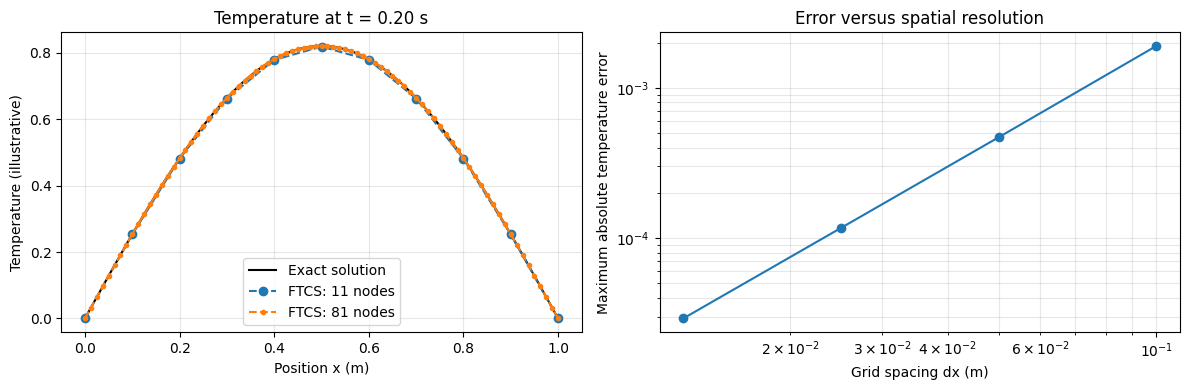

In [ ]:
# @title 💻 Example 2: Refine the grid while retaining a stable time step

# This example uses ftcs_history() from Example 1.
# If you restarted the notebook, run Example 1 first.

# ============================================================
# 1. DEFINE A KNOWN SOLUTION FOR CHECKING NUMERICAL ERROR
# ============================================================

def exact_temperature(x, t, D, L):
    """Exact sine-mode solution of the 1D diffusion equation."""
    decay = np.exp(-D * (np.pi / L)**2 * t)
    return decay * np.sin(np.pi * x / L)


L = 1.0                         # Rod length (m)
D = 0.10                        # Same illustrative diffusivity (m^2/s)
final_time = 0.20               # Compare EVERY grid at this physical time (s)
r_target = 0.4                 # Stable and below the FTCS limit of 0.50
node_counts = [11, 21, 41, 81] # Including both boundary nodes

records = []                    # Collect values for printed output and plots

# ============================================================
# 2. RUN THE SAME PROBLEM WITH FOUR DIFFERENT GRID RESOLUTIONS
# ============================================================

for Nx in node_counts:
    x = np.linspace(0, L, Nx)   # Create this grid's node positions
    dx = x[1] - x[0]            # Spatial spacing on this grid

    # First calculate the time step that gives the target r.
    dt_suggested = r_target * dx**2 / D

    # Use a whole number of steps that lands EXACTLY on final_time.
    # Rounding UP the count ensures the actual dt is no larger.
    number_of_steps = int(np.ceil(final_time / dt_suggested))
    dt = final_time / number_of_steps
    r_actual = D * dt / dx**2

    # Check that this simulation meets the known FTCS limit.
    assert r_actual <= 0.5 + 1e-12

    T_initial = np.sin(np.pi * x / L)
    T_numeric = ftcs_history(T_initial, r_actual, number_of_steps)[-1]
    T_exact = exact_temperature(x, final_time, D, L)

    # Compare on IDENTICAL grid locations and at the SAME time.
    max_error = np.max(np.abs(T_numeric - T_exact))

    # Count interior-node updates as a simple measure of work.
    work = (Nx - 2) * number_of_steps
    records.append((Nx, dx, dt, r_actual, number_of_steps,
                    work, max_error, x, T_numeric))


# ============================================================
# 3. PRINT THE STABILITY, ERROR AND WORK FOR EACH GRID
# ============================================================

print('Nodes      dx (m)     dt (s)      r       Steps   Updates    Max error')
print('-' * 78)
for Nx, dx, dt, r_actual, nsteps, work, error, x, T_num in records:
    print(f'{Nx:5d}   {dx:10.5f}  {dt:10.6f}   {r_actual:5.3f}'
          f'   {nsteps:6d}   {work:7d}   {error:10.3e}')

print('\nRelative work increase between consecutive grids:')
for previous, current in zip(records[:-1], records[1:]):
    print(f'{previous[0]:2d} -> {current[0]:2d} nodes: '
          f'{current[5] / previous[5]:.2f}x')


# ============================================================
# 4. COMPARE THE NUMERICAL SOLUTIONS AGAINST THE EXACT SOLUTION
# ============================================================

fine_x = np.linspace(0, L, 401)
fine_exact = exact_temperature(fine_x, final_time, D, L)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# On the left, compare the coarsest and finest grids at the SAME time.
axes[0].plot(fine_x, fine_exact, 'k-', label='Exact solution')
for item, marker in [(records[0], 'o--'), (records[-1], '.--')]:
    Nx, _, _, _, _, _, _, grid_x, T_num = item
    axes[0].plot(grid_x, T_num, marker, label=f'FTCS: {Nx} nodes')
axes[0].set_xlabel('Position x (m)')
axes[0].set_ylabel('Temperature (illustrative)')
axes[0].set_title(f'Temperature at t = {final_time:.2f} s')
axes[0].legend()
axes[0].grid(alpha=0.3)

# On the right, plot the error as the grid spacing is reduced.
dx_values = [item[1] for item in records]
error_values = [item[6] for item in records]
axes[1].loglog(dx_values, error_values, 'o-')
axes[1].set_xlabel('Grid spacing dx (m)')
axes[1].set_ylabel('Maximum absolute temperature error')
axes[1].set_title('Error versus spatial resolution')
axes[1].grid(alpha=0.3, which='both')

plt.tight_layout()
plt.show()

**How to read Example 2:**

1. The **diffusion number stays below the FTCS limit** on every grid. Refining $\Delta x$ without adjusting $\Delta t$ could otherwise make a previously stable simulation unstable.
2. The **error decreases** as the grid becomes finer. In this smooth, carefully chosen example, the approximation is approaching the known analytical result. This is evidence of **numerical convergence**, not validation of a real physical experiment.
3. The number of interior-node updates rises by roughly a factor of **eight** whenever the spatial spacing is halved. Extra accuracy therefore has a computational cost.
4. The curves on the left may look almost identical even when their errors differ. **A visually smooth, plausible curve is not sufficient evidence of accuracy.** The error plot and numerical table make the difference visible.

Here $r$ is kept approximately constant as the grid is refined. Therefore both the spatial error and the temporal error are changing. This experiment checks the **combined numerical result**, rather than isolating the order of either discretisation alone.

> **Try it:** Change `r_target = 0.40` to `r_target = 0.20`. Compare the error and step counts. Did reducing the time step improve the result as much as you expected, and was that improvement worth the additional work?

## 📂 11.4.6 Stability, accuracy and convergence are different checks

At this stage we have encountered several ideas that sound similar but answer **different questions**:

| Check | Main question | Example |
|---|---|---|
| **Time-marching stability** | Do small numerical disturbances remain controlled over time? | Is $r\le0.5$ for this FTCS diffusion scheme? |
| **Numerical accuracy** | How close is the discrete result to the intended PDE solution? | Compare $T_{\mathrm{FTCS}}$ with the analytical sine-mode solution. |
| **Grid/time-step convergence** | Does the numerical answer approach a limiting result as discretisation is refined appropriately? | Compare results on 11, 21, 41 and 81 nodes at the same time. |
| **Linear-solver convergence** | Has an iterative algorithm adequately solved its current algebraic equations? | Jacobi or Gauss–Seidel residual in Notebook 11.3. |

A solution can satisfy the FTCS stability condition and still be **inaccurate** because the grid or time step is too coarse. Similarly, a tiny matrix residual in an elliptic PDE calculation means its discrete equations have been solved closely; it does **not** establish that the spatial grid is fine enough.

Notebook 11.1 introduced the principle that, for an appropriate **well-posed linear initial-value problem**, *consistency plus stability* gives convergence as the discretisation is refined. In practice, we should still **check numerical convergence**, compare against available analytical or benchmark solutions, and assess whether the PDE model and input data represent the actual engineering system.

> **Remember:** Stable $\ne$ accurate $\ne$ physically validated. Numerical convergence and physical validation provide different types of evidence.

## 📂 11.4.7 Why would we use an implicit method?

FTCS is straightforward because every value at the next time level can be calculated using known values from the current time level. However, Example 2 revealed an important limitation: **a fine spatial grid can force an extremely small explicit time step**.

An **implicit** time-marching method instead involves unknown temperatures at the **new** time level. These values are coupled, so we generally solve a linear system at each physical time step, in a form familiar from Notebook 11.3:

$$A\mathbf T^{n+1}=\mathbf b.$$

For the standard linear diffusion problem, common implicit schemes can avoid the restrictive FTCS time-step limit. However, **a method that remains stable at a large time step may still be inaccurate**. Implicit schemes also require additional computation to solve the coupled equations.

The next notebook, **11.5 Crank–Nicolson**, will develop a method that averages the spatial diffusion terms at the current and new time levels. It offers **second-order temporal accuracy** and is unconditionally stable for the standard linear diffusion equation, although excessively large steps can still produce poorly damped numerical oscillations.

For now, the essential choice is clear: **explicit simplicity and cheap individual steps** versus **implicit linear solves and different stability–accuracy trade-offs**.

# ✅ Key takeaways and practice

- **FTCS stability for 1D diffusion:** $r=D\Delta t/(\Delta x)^2\le1/2$ for the standard constant-$D$, uniform-grid scheme.
- **An alternating error is not necessarily unstable:** its magnitude may decrease even if its sign changes at each step.
- **Courant versus Fourier:** advection time-step restrictions commonly scale with $\Delta x$; explicit diffusion restrictions commonly scale with $(\Delta x)^2$.
- **Experiment before committing:** Use the interactive controls to check whether a selected pair of spatial and temporal discretisations satisfies the FTCS condition.
- **Finer grids can be expensive:** halving $\Delta x$ in 1D FTCS diffusion typically requires four times as many time steps and about eight times as many grid-node updates for the same physical duration.
- **Different checks answer different questions:** stability, numerical accuracy, grid convergence, iterative-solver convergence and physical validation should not be confused.

### 🚀 Quick practice

1. For $D=0.05\;\mathrm{m^2/s}$ and $\Delta x=0.01\;\mathrm m$, calculate the **largest stable FTCS time step**. *(Check: $0.001\;\mathrm s$.)*
2. An error is multiplied by $-0.7$ after each step. Is it unstable? Explain the **sign** and **magnitude** separately.
3. A stable 1D FTCS simulation uses $\Delta x=0.04\;\mathrm m$. If this spacing is halved, what happens to the maximum stable time step? What happens to the **approximate node-update cost** for a fixed physical duration?
4. Jacobi iteration has reached a tiny residual for a discrete Laplace equation, but the result changes considerably when the grid is refined. Which calculation has converged, and which has not yet been demonstrated?

Use the interactive explorer as an additional check, and try to **predict → calculate → run → inspect → explain** rather than relying only on the appearance of the plotted solution.

# 🔗 Bridge to Notebook 11.5 — Crank–Nicolson

We have seen **why stability conditions matter** and how a more refined spatial grid can make explicit FTCS time marching increasingly expensive. The next question is:

> **Can we advance a diffusion solution using a larger time step without suffering the same FTCS stability restriction?**

In **Notebook 11.5**, we will develop the **Crank–Nicolson method**, set up the coupled equations for the new time level, solve the resulting linear system, and compare its stability, accuracy and computational work with the explicit FTCS method.

# 📚 References and source notes (optional further reading)

- **Chapra, S. C. and Canale, R. P.** *Numerical Methods for Engineers*, 8th ed., **§30.2–30.2.1 (pp. 887–891)**: explicit diffusion methods, convergence, the stability limit and illustrations of instability. **§30.3–30.4** introduces implicit methods and Crank–Nicolson; these will be developed in Notebook 11.5.
- **LeVeque, R. J.** *Finite Difference Methods for Ordinary and Partial Differential Equations*, SIAM (2007), **§9.1–9.6 (pp. 183–195)**: truncation errors, the effect of spatial resolution on time-step restrictions, stability and von Neumann analysis. **§10.7 (pp. 215–217)** discusses the CFL condition for advection.

The derivations and two Python investigations in this notebook are deliberately **less advanced than the full textbook treatments**. The focus is to support an introductory engineering numerical-methods course.

# 🤖 AI Acknowledgment

This teaching notebook was prepared with assistance from OpenAI ChatGPT (GPT-6) for drafting Python examples and grammatical proofreading. Its examples were executed and checked for numerical consistency during drafting. All outputs from the LLM were proofread and edited by the teaching team (YCV) before final release.